# 02 — Gaussian Naive Bayes

Khảo sát smoothing, chọn cấu hình bằng validation và đối chiếu với sklearn. Mô hình tự viết nằm trong `src/models/gaussian.py`; lý thuyết chi tiết trình bày trong report.

Chạy từ thư mục gốc đồ án hoặc `notebooks/`. Kết quả được lưu tại `results/gaussian/`.


## 1. Import và nạp dữ liệu

Dùng cùng split 50.000 train / 10.000 validation / 10.000 test, seed 42. Ảnh đã chia 255 và làm phẳng; đổi sang float64 để đối chiếu số học với sklearn.


In [1]:
from pathlib import Path
import sys, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.naive_bayes import GaussianNB as SklearnGaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import load_prepared_mnist
from src.models.gaussian import GaussianNB

SEED, BATCH_SIZE = 42, 512
OUTPUT = ROOT / 'results' / 'gaussian'
OUTPUT.mkdir(parents=True, exist_ok=True)
X_all, y_all, X_test, y_test = load_prepared_mnist()
X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=10000, stratify=y_all, random_state=SEED)
X_train, X_val, X_test = [X.astype(np.float64) for X in (X_train, X_val, X_test)]
del X_all
print('Train:', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test:', X_test.shape, y_test.shape)


Train: (50000, 784) (50000,)
Validation: (10000, 784) (10000,)
Test: (10000, 784) (10000,)


## 2. Hàm dự đoán và đánh giá

Chia batch khi dự đoán để tránh mảng trung gian `(N, 10, 784)` quá lớn. Dùng cùng batch cho cả hai cài đặt.


In [2]:
def predict_batches(model, X):
    return np.concatenate([model.predict(X[i:i+BATCH_SIZE]) for i in range(0, len(X), BATCH_SIZE)])

def metrics(y, pred):
    precision, recall, f1, _ = precision_recall_fscore_support(y, pred, labels=np.arange(10), average='macro', zero_division=0)
    return dict(accuracy=accuracy_score(y, pred), precision_macro=precision, recall_macro=recall, f1_macro=f1)


## 3. Khảo sát smoothing và chọn cấu hình

Trong bản tự viết, `var_smoothing` là epsilon cộng trực tiếp vào phương sai. Chọn **accuracy validation cao nhất**, sau đó F1 macro; nếu vẫn hòa thì chọn epsilon nhỏ hơn. Không dùng test trong bước này.


,epsilon,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,1e-12,0.5313,0.65869,0.52320,0.47863,0.25398,0.99029
1,1e-09,0.5648,0.68284,0.55692,0.52529,0.27397,1.05636
2,1e-06,0.6279,0.71986,0.62050,0.60442,0.27331,1.05604
3,1e-03,0.7635,0.79085,0.75874,0.76000,0.29260,1.12759
4,1e-01,0.7594,0.80163,0.75344,0.75938,0.27394,1.03268
5,1e+00,0.6594,0.79019,0.65082,0.66943,0.28173,1.02787


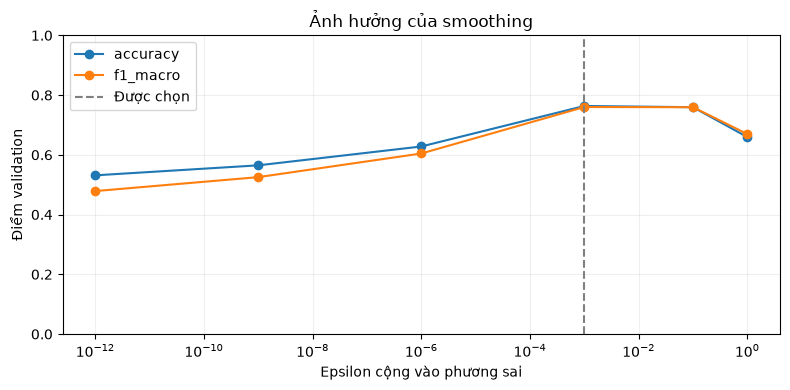

Chọn epsilon=0.001: accuracy=76.35%, F1 macro=0.7600.
Accuracy chênh baseline 1e-9: +19.87 điểm phần trăm.


In [3]:
EPS_VALUES = [1e-12, 1e-9, 1e-6, 1e-3, 1e-1, 1.0]
models, val_predictions, rows = {}, {}, []
for epsilon in EPS_VALUES:
    model = GaussianNB(var_smoothing=epsilon)
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - start
    start = time.perf_counter()
    pred = predict_batches(model, X_val)
    predict_s = time.perf_counter() - start
    models[epsilon], val_predictions[epsilon] = model, pred
    rows.append(dict(epsilon=epsilon, **metrics(y_val, pred), fit_seconds=fit_s, predict_seconds=predict_s))
tuning = pd.DataFrame(rows)
best = tuning.sort_values(['accuracy', 'f1_macro', 'epsilon'], ascending=[False, False, True]).iloc[0]
epsilon = float(best.epsilon)
manual = models[epsilon]
display(tuning.round(5).assign(epsilon=tuning.epsilon.map(lambda x: f'{x:.0e}')))

fig, ax = plt.subplots(figsize=(8, 4))
for metric in ['accuracy', 'f1_macro']:
    ax.semilogx(tuning.epsilon, tuning[metric], marker='o', label=metric)
ax.axvline(epsilon, color='gray', linestyle='--', label='Được chọn')
ax.set(xlabel='Epsilon cộng vào phương sai', ylabel='Điểm validation', ylim=(0, 1), title='Ảnh hưởng của smoothing')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
fig.savefig(OUTPUT / 'smoothing_validation.png', dpi=300)
plt.show()
baseline = tuning.loc[tuning.epsilon == 1e-9].iloc[0]
print(f'Chọn epsilon={epsilon:g}: accuracy={best.accuracy:.2%}, F1 macro={best.f1_macro:.4f}.')
print(f'Accuracy chênh baseline 1e-9: {(best.accuracy-baseline.accuracy)*100:+.2f} điểm phần trăm.')


**Nhận xét:** mức làm trơn ảnh hưởng rõ đến kết quả Gaussian NB. Cấu hình được chọn chỉ tốt nhất trong lưới đã thử trên split hiện tại; giữ cấu hình này để đánh giá cuối.


## 4. Kiểm chứng với sklearn

Sklearn cộng `var_smoothing * max_j Var(X_train[:, j])` vào phương sai. Vì vậy phải quy đổi tham số để **cùng epsilon**, không so sánh chỉ dựa trên cùng con số `var_smoothing`. Kiểm tra prior, mean, variance và dự đoán validation; không cần lặp nhiều thí nghiệm posterior.


In [4]:
max_var = X_train.var(axis=0).max()
reference = SklearnGaussianNB(var_smoothing=epsilon / max_var)
start = time.perf_counter()
reference.fit(X_train, y_train)
reference_fit_s = time.perf_counter() - start
check_rows = []
for name, a, b in [('prior', manual.priors_, reference.class_prior_),
                   ('mean', manual.means_, reference.theta_), ('variance', manual.vars_, reference.var_)]:
    check_rows.append(dict(parameter=name, max_abs_error=np.abs(a-b).max(), matched=np.allclose(a, b, rtol=1e-10, atol=1e-12)))
parameter_check = pd.DataFrame(check_rows)
display(parameter_check)
start = time.perf_counter()
reference_val_pred = predict_batches(reference, X_val)
reference_val_s = time.perf_counter() - start
print('Thứ tự lớp khớp:', np.array_equal(manual.classes_, reference.classes_))
print(f'Nhãn validation trùng nhau: {np.mean(val_predictions[epsilon] == reference_val_pred):.2%}')


,parameter,max_abs_error,matched
0,prior,0.0,True
1,mean,0.0,True
2,variance,0.0,True


Thứ tự lớp khớp: True
Nhãn validation trùng nhau: 100.00%


**Nhận xét:** tham số khớp trong dung sai và dự đoán trùng nhau hỗ trợ kiểm chứng cài đặt trên dữ liệu này. Đây không phải chứng minh chương trình đúng trong mọi trường hợp.


## 5. Đánh giá cấu hình cuối

Đánh giá cùng mô hình trên train, validation và test; không fit lại trên train + validation. Train là in-sample, validation đã dùng chọn tham số, test là đánh giá cuối. `fit_seconds` là thời gian fit riêng cấu hình cuối, không phải tổng thời gian tìm kiếm. Thời gian đo một lần, phụ thuộc máy và tải hệ thống.


,model,split,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,GaussianNB tự viết,Train,0.76832,0.79230,0.76344,0.76409,0.29260,5.17900
1,GaussianNB tự viết,Validation,0.76350,0.79085,0.75874,0.76000,0.29260,1.12759
2,GaussianNB tự viết,Test,0.77530,0.80187,0.77068,0.77161,0.29260,1.05304
3,GaussianNB sklearn,Train,0.76832,0.79230,0.76344,0.76409,0.44591,3.30948
4,GaussianNB sklearn,Validation,0.76350,0.79085,0.75874,0.76000,0.44591,0.68066
5,GaussianNB sklearn,Test,0.77530,0.80187,0.77068,0.77161,0.44591,0.66067


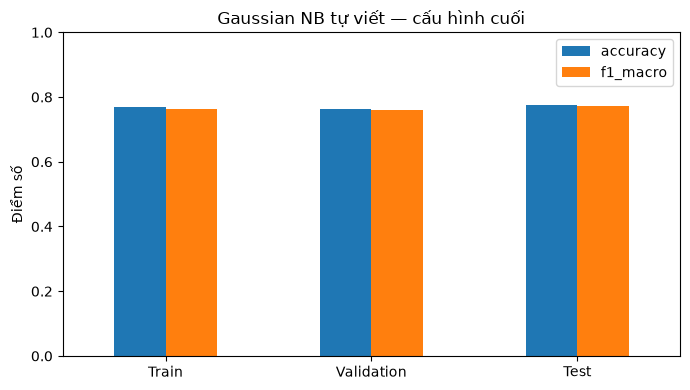

Test accuracy: 77.53%; F1 macro: 0.7716.
Nhãn test trùng sklearn: 100.00%


In [5]:
datasets = {'Train': (X_train, y_train), 'Validation': (X_val, y_val), 'Test': (X_test, y_test)}
final_models = {'GaussianNB tự viết': manual, 'GaussianNB sklearn': reference}
rows, predictions = [], {}
for name, model in final_models.items():
    for split, (X, y) in datasets.items():
        if split == 'Validation':
            pred = val_predictions[epsilon] if name == 'GaussianNB tự viết' else reference_val_pred
            predict_s = best.predict_seconds if name == 'GaussianNB tự viết' else reference_val_s
        else:
            start = time.perf_counter()
            pred = predict_batches(model, X)
            predict_s = time.perf_counter() - start
        predictions[name, split] = pred
        rows.append(dict(model=name, split=split, **metrics(y, pred),
            fit_seconds=best.fit_seconds if name == 'GaussianNB tự viết' else reference_fit_s,
            predict_seconds=predict_s))
results = pd.DataFrame(rows)
display(results.round(5))
manual_results = results[results.model == 'GaussianNB tự viết'].set_index('split')
fig, ax = plt.subplots(figsize=(7, 4))
manual_results[['accuracy', 'f1_macro']].plot.bar(ax=ax, rot=0, ylim=(0, 1))
ax.set(xlabel='', ylabel='Điểm số', title='Gaussian NB tự viết — cấu hình cuối')
fig.tight_layout(); fig.savefig(OUTPUT / 'final_scores.png', dpi=300)
plt.show()
print(f'Test accuracy: {manual_results.loc["Test", "accuracy"]:.2%}; F1 macro: {manual_results.loc["Test", "f1_macro"]:.4f}.')
print(f'Nhãn test trùng sklearn: {np.mean(predictions["GaussianNB tự viết", "Test"] == predictions["GaussianNB sklearn", "Test"]):.2%}')


## 6. Phân tích lỗi trên test

Chỉ vẽ confusion matrix của mô hình tự viết để tránh lặp hình. Hàng là nhãn thật, cột là dự đoán. Bảng theo lớp giúp xác định lớp có precision/recall thấp.


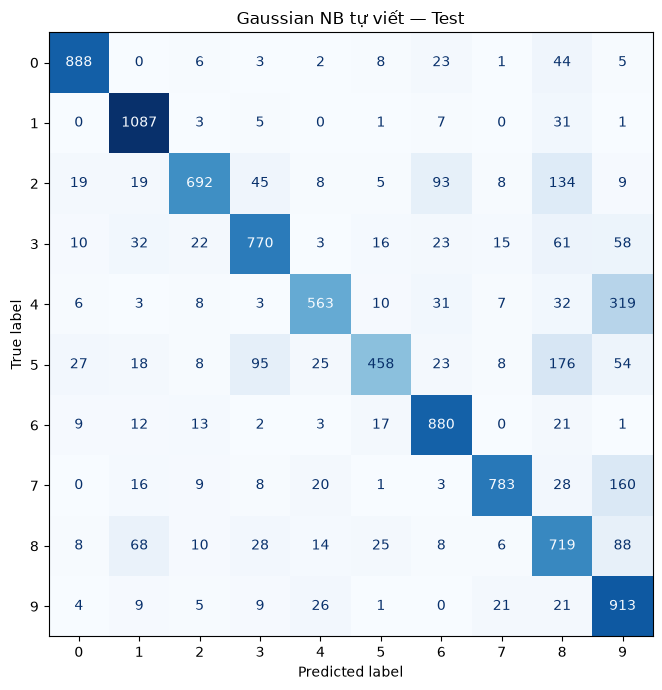

,precision,recall,f1-score,support
0,0.9145,0.9061,0.9103,980.0
1,0.8600,0.9577,0.9062,1135.0
2,0.8918,0.6705,0.7655,1032.0
3,0.7955,0.7624,0.7786,1010.0
4,0.8479,0.5733,0.6841,982.0
5,0.8450,0.5135,0.6388,892.0
6,0.8066,0.9186,0.8590,958.0
7,0.9223,0.7617,0.8343,1028.0
8,0.5675,0.7382,0.6417,974.0
9,0.5678,0.9049,0.6977,1009.0


Lớp có recall thấp nhất: 5


In [6]:
test_pred = predictions['GaussianNB tự viết', 'Test']
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels=np.arange(10), ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Gaussian NB tự viết — Test')
fig.tight_layout(); fig.savefig(OUTPUT / 'confusion_test.png', dpi=300)
plt.show()
report = pd.DataFrame(classification_report(y_test, test_pred, output_dict=True, zero_division=0)).T
display(report.loc[[str(k) for k in range(10)]].round(4))
class_report = report.loc[[str(k) for k in range(10)]]
print('Lớp có recall thấp nhất:', class_report.recall.idxmin())


**Nhận xét:** Gaussian NB bỏ qua phụ thuộc giữa các pixel và giả định phân phối Gaussian cho từng pixel. Đây là hạn chế cần thảo luận trong report; chỉ kết luận hơn/kém các phương pháp khác sau khi có bảng so sánh cùng split.


## 7. Lưu kết quả

Xuất độ đo, khảo sát, bảng kiểm chứng, confusion matrix từng split và tham số mô hình. Hình PNG 300 dpi được lưu ở các ô phía trên. Chạy lại ghi đè file cùng tên.


In [7]:
for name, table in {'metrics': results, 'smoothing': tuning, 'parameter_check': parameter_check}.items():
    table.to_csv(OUTPUT / f'{name}.csv', index=False)
results.query("model == 'GaussianNB tự viết' and split == 'Test'").to_csv(OUTPUT / 'comparison.csv', index=False)
report.to_csv(OUTPUT / 'classification_report_test.csv')
for split, (_, y) in datasets.items():
    cm = confusion_matrix(y, predictions['GaussianNB tự viết', split], labels=np.arange(10))
    pd.DataFrame(cm, index=np.arange(10), columns=np.arange(10)).to_csv(OUTPUT / f'confusion_{split.lower()}.csv', index_label='true_digit')
np.savez_compressed(OUTPUT / 'manual_parameters.npz', classes=manual.classes_, priors=manual.priors_, means=manual.means_, variances=manual.vars_)
config = dict(seed=SEED, epsilon=epsilon, sklearn_var_smoothing=float(epsilon/max_var), batch_size=BATCH_SIZE,
    train_samples=len(y_train), validation_samples=len(y_val), test_samples=len(y_test), dtype='float64',
    selection='accuracy, f1_macro; hoa thi epsilon nho hon', search_fit_seconds=float(tuning.fit_seconds.sum()))
(OUTPUT / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu kết quả:', OUTPUT)


Đã lưu kết quả: d:\Nhận dạng mẫu\mnist\results\gaussian
